# XGBoost pCO2 Climatology

## 0. Imports & Setup

In [ ]:
import gc
import os
import random
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
import xgboost as xgb
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from utils.runtime import set_seed

SEED = 42
set_seed(SEED)

from utils.paths import (
    SATELLITE_COVARIATES_ZARR,
    NOAA_MBL_ZARR,
    SOCAT_ZARR,
    XGBOOST_THERMAL_ZARR,
    ensure_project_dirs,
    print_paths,
    assert_exists
)

ensure_project_dirs()

assert_exists(SATELLITE_COVARIATES_ZARR, "Satellite covariates Zarr")
assert_exists(NOAA_MBL_ZARR, "NOAA GML marine boundary-layer CO2 Zarr")
assert_exists(SOCAT_ZARR, "Processed SOCAT gridded monthly Zarr")

SATELLITE_LOAD_PATH = SATELLITE_COVARIATES_ZARR
XCO2_LOAD_PATH = NOAA_MBL_ZARR
SOCAT_LOAD_PATH = SOCAT_ZARR
THERMAL_SAVE_PATH = XGBOOST_THERMAL_ZARR

print_paths(
    ("Satellite covariates", SATELLITE_COVARIATES_ZARR),
    ("NOAA xCO2", NOAA_MBL_ZARR),
    ("SOCAT", SOCAT_ZARR),
    ("XGBoost thermal output", XGBOOST_THERMAL_ZARR)
)

Satellite covariates: /scratch/antwerpen/grp/ap_vliz_research/PPFC/evie.stergiopoulou/HYDRA-pCO2/data/processed/satellite/satellite_covariates_1deg_1970_2024.zarr
NOAA xCO2: /scratch/antwerpen/grp/ap_vliz_research/PPFC/evie.stergiopoulou/HYDRA-pCO2/data/processed/satellite/noaa_gml_mbl_co2_1x1_monthly.zarr
SOCAT: /scratch/antwerpen/grp/ap_vliz_research/PPFC/evie.stergiopoulou/HYDRA-pCO2/data/processed/socat/SOCATv2026_gridded_monthly.zarr
XGBoost thermal output: /scratch/antwerpen/grp/ap_vliz_research/PPFC/evie.stergiopoulou/HYDRA-pCO2/data/processed/xgboost_thermal/pco2_thermal_xgboost_1993_2024_1deg_monthly.zarr


#### Settings

In [ ]:
# Common period
START_DATE = "1993-01-01"
END_DATE = "2024-12-31" # to include mid month SOCAT

# Monthly timestamps used for final thermal output
MONTHLY_TIMES = pd.date_range(START_DATE, END_DATE, freq="MS")

print("Period years:", START_DATE, "to", END_DATE)
print("Number of monthly output steps:", len(MONTHLY_TIMES)) # 384 if 1993-2024

## 1. Load Data

In [ ]:
# Load satellite
ds_sat = xr.open_zarr(SATELLITE_LOAD_PATH, consolidated=True).sel(time=slice(START_DATE, END_DATE))

print(f"Loaded satellite covariates: {SATELLITE_LOAD_PATH}")
print(f"Variables: {list(ds_sat.data_vars)}")
print(f"Dimensions: {dict(ds_sat.sizes)}")
print(f"Time: {str(ds_sat.time.values[0])[:10]} to {str(ds_sat.time.values[-1])[:10]}")

# Load SOCAT
# Only load variables needed for training
SOCAT_VARS = ["pco2_ave_weighted", "fco2_count_nobs"]

ds_socat = xr.open_zarr(SOCAT_LOAD_PATH, consolidated=True)[SOCAT_VARS].sel(time=slice(START_DATE, END_DATE))

print(f"\nLoaded SOCAT: {SOCAT_LOAD_PATH}")
print(f"Variables: {list(ds_socat.data_vars)}")
print(f"Dimensions: {dict(ds_socat.sizes)}")
print(f"Time: {str(ds_socat.time.values[0])[:10]} to {str(ds_socat.time.values[-1])[:10]}")

PCO2_VAR = "pco2_ave_weighted"
NOBS_VAR = "fco2_count_nobs"  # used as observation-count mask
assert PCO2_VAR in ds_socat.data_vars, f"{PCO2_VAR} not found - check 02_socat_exploration output"

# Load xCO2
ds_xco2 = xr.open_zarr(XCO2_LOAD_PATH, consolidated=True,).sel(time=slice(START_DATE, END_DATE))

XCO2_VAR = "atm_co2_xco2"
assert XCO2_VAR in ds_xco2.data_vars, f"{XCO2_VAR} not found. Available: {list(ds_xco2.data_vars)}"

print(f"\nLoaded NOAA xCO2: {XCO2_LOAD_PATH}")
print(f"Variables: {list(ds_xco2.data_vars)}")
print(f"Dimensions: {dict(ds_xco2.sizes)}")
print(f"Time: {str(ds_xco2.time.values[0])[:10]} to {str(ds_xco2.time.values[-1])[:10]}")

print("Attributes", ds_xco2[XCO2_VAR].attrs)

Loaded satellite covariates: /scratch/antwerpen/grp/ap_vliz_research/PPFC/evie.stergiopoulou/HYDRA-pCO2/data/processed/satellite/satellite_covariates_1deg_1970_2024.zarr
Variables: ['chlos', 'chlos_anom', 'mlotst', 'mlotst_anom', 'sos', 'sos_anom', 'tos', 'tos_anom']
Dimensions: {'time': 384, 'lat': 180, 'lon': 360}
Time: 1993-01-01 to 2024-12-01

Loaded SOCAT: /scratch/antwerpen/grp/ap_vliz_research/PPFC/evie.stergiopoulou/HYDRA-pCO2/data/processed/socat/SOCATv2026_gridded_monthly.zarr
Variables: ['pco2_ave_weighted', 'fco2_count_nobs']
Dimensions: {'time': 384, 'lat': 180, 'lon': 360}
Time: 1993-01-16 to 2024-12-16

Loaded NOAA xCO2: /scratch/antwerpen/grp/ap_vliz_research/PPFC/evie.stergiopoulou/HYDRA-pCO2/data/processed/satellite/noaa_gml_mbl_co2_1x1_monthly.zarr
Variables: ['atm_co2_xco2']
Dimensions: {'time': 384, 'lat': 180, 'lon': 360}
Time: 1993-01-01 to 2024-12-01
Attributes {'citation': 'Lan, X., Tans, P., Thoning, K., & NOAA Global Monitoring Laboratory. (2024). NOAA Greenh

In [6]:
print("Grid and time checks")

# Confirm expected coordinate conventions
for name, da in [("satellite", ds_sat["tos"]), ("SOCAT", ds_socat[PCO2_VAR]), ("NOAA xCO2", ds_xco2[XCO2_VAR])]:
    print(f"{name}: lat={float(da.lat.min()):.2f} to {float(da.lat.max()):.2f}, lon={float(da.lon.min()):.2f} to {float(da.lon.max()):.2f}")

# Satellite and SOCAT must be on the same 1deg grid.
assert np.allclose(ds_sat.lat.values, ds_socat.lat.values)
assert np.allclose(ds_sat.lon.values, ds_socat.lon.values)

# NOAA was created on the same target grid
assert np.allclose(ds_sat.lat.values, ds_xco2.lat.values)
assert np.allclose(ds_sat.lon.values, ds_xco2.lon.values)

# after subsetting, all should have 384 months
assert ds_sat.sizes["time"] == 384
assert ds_xco2.sizes["time"] == 384
assert ds_socat.sizes["time"] == 384

print("All grid and time checks passed")

Grid and time checks
satellite: lat=-89.50 to 89.50, lon=-179.50 to 179.50
SOCAT: lat=-89.50 to 89.50, lon=-179.50 to 179.50
NOAA xCO2: lat=-89.50 to 89.50, lon=-179.50 to 179.50
All grid and time checks passed


## 2. Preprocessing

### Build SOCAT training table

In [7]:
# Extract only valid SOCAT pCO2 observations
socat_pco2 = ds_socat[PCO2_VAR].load()
socat_nobs = ds_socat[NOBS_VAR].load()

pco2_values = socat_pco2.values
nobs_values = socat_nobs.values

valid = np.isfinite(pco2_values) & (nobs_values>0)

time_idx, lat_idx, lon_idx = np.where(valid)

socat_df = pd.DataFrame({
    "time": ds_socat.time.values[time_idx],
    "lat": ds_socat.lat.values[lat_idx],
    "lon": ds_socat.lon.values[lon_idx],
    "pco2": pco2_values[time_idx, lat_idx, lon_idx],
})

del socat_pco2
del socat_nobs
del pco2_values
del nobs_values

gc.collect()

# Convert SOCAT mid-month timestamps to calendar month IDs
socat_df["time"] = pd.to_datetime(socat_df["time"])
socat_df["month"] = socat_df["time"].dt.month
socat_df["time_month"] = (
    socat_df["time"]
    .values
    .astype("datetime64[M]")
)

print("SOCAT training rows:", f"{len(socat_df):,}")
print("SOCAT observation range:", socat_df["time"].min(), "to", socat_df["time"].max())
print("pCO2 summary:")
display(socat_df["pco2"].describe())

SOCAT training rows: 352,600
SOCAT observation range: 1993-01-16 12:00:00 to 2024-12-16 12:00:00
pCO2 summary:


count    352600.000000
mean        364.792247
std          44.860926
min          44.671488
25%         342.365635
50%         365.590527
75%         389.601120
max        4324.314488
Name: pco2, dtype: float64

### Attach latitude-resolved NOAA xCO2 to each SOCAT observation.

NOAA xCO2 varies with latitude and time, but is uniform in longitude.
Each SOCAT observation therefore receives the NOAA value corresponding to its calendar month and nearest latitude.

In [8]:
xco2_field = (
    ds_xco2[XCO2_VAR]
    .load()
)

assert xco2_field.dims == ("time", "lat", "lon")
assert xco2_field.sizes["time"] == 384
assert xco2_field.sizes["lat"] == 180
assert xco2_field.sizes["lon"] == 360

assert xco2_field.attrs["units"] == "ppm"

# Convert both datasets to calendar-month IDs
xco2_time_month = xco2_field.time.values.astype("datetime64[M]")
socat_time_month = socat_df["time_month"].values

# Check every SOCAT month has an atmospheric value
missing_xco2_months = np.setdiff1d(
    np.unique(socat_time_month),
    np.unique(xco2_time_month),
)

assert len(missing_xco2_months) == 0, (
    f"Missing NOAA xCO2 months: {missing_xco2_months}"
)

# Build lookup by month
xco2_by_month = (
    xco2_field
    .assign_coords(
        time_month=("time", xco2_time_month)
    )
    .swap_dims({"time": "time_month"})
)

# Select NOAA xCO2 at the month and nearest SOCAT latitude
# longitude irrelevant bc zonally uniform

obs_month_xr = xr.DataArray(
    socat_df["time_month"].values,
    dims="obs",
)

obs_lat_xr = xr.DataArray(
    socat_df["lat"].values,
    dims="obs",
)

sampled_xco2 = (
    xco2_by_month
    .sel(
        time_month=obs_month_xr,
        lat=obs_lat_xr,
        lon=0,
        method="nearest",
    )
    .compute()
)

socat_df["xco2"] = sampled_xco2.values

assert socat_df["xco2"].notna().all()
assert socat_df["xco2"].between(250, 500).all()

print("Latitude-resolved NOAA xCO2 attached")
print("Units:", ds_xco2[XCO2_VAR].attrs["units"])
print("xCO2 summary:")
display(socat_df["xco2"].describe())

Latitude-resolved NOAA xCO2 attached
Units: ppm
xCO2 summary:


count    352600.000000
mean        392.843140
std          17.806116
min         348.087280
25%         379.984100
50%         393.443481
75%         406.864349
max         430.812500
Name: xco2, dtype: float64

### Construct the detrended pCO2 target
Remove the atmospheric CO2 trend from observed ocean pCO2, following Gregor's apporach. Result in micro atmospheres still.

In [9]:
socat_df["delta_pco2"] = socat_df["pco2"] - socat_df["xco2"]

print("Detrended target: delta_pco2")
display(socat_df["delta_pco2"].describe())

print("Mean pCO2:", socat_df["pco2"].mean())
print("Mean atmospheric xCO2:", socat_df["xco2"].mean())
print("Mean delta_pco2:", socat_df["delta_pco2"].mean())

Detrended target: delta_pco2


count    352600.000000
mean        -28.050923
std          43.997430
min        -370.528067
25%         -49.265466
50%         -25.720833
75%          -5.503743
max        3933.908878
Name: delta_pco2, dtype: float64

Mean pCO2: 364.792246578769
Mean atmospheric xCO2: 392.84314
Mean delta_pco2: -28.05092299749398


### Inspect observed pco2 distribution

Largest pCO2 values:


,time,lat,lon,pco2,xco2,delta_pco2
151011,2010-11-16 00:00:00,25.5,-81.5,4324.314488,390.405609,3933.908878
166884,2011-11-16 00:00:00,25.5,-81.5,3482.846073,392.194580,3090.651493
313489,2021-09-16 00:00:00,0.5,-49.5,1281.727433,413.860107,867.867326
79836,2005-06-16 00:00:00,43.5,-69.5,1174.431134,381.902466,792.528668
91891,2006-06-16 00:00:00,43.5,-69.5,1054.706091,384.492279,670.213812
81881,2005-08-16 12:00:00,43.5,-69.5,943.922704,373.410614,570.512090
313501,2021-09-16 00:00:00,1.5,-49.5,897.397815,413.753357,483.644458
94737,2006-08-16 12:00:00,43.5,-69.5,894.852204,374.948822,519.903382
83916,2005-10-16 12:00:00,43.5,-69.5,861.901690,377.758881,484.142809
329270,2022-12-16 12:00:00,49.5,-124.5,830.989555,424.119110,406.870445


Smallest pCO2 values:


,time,lat,lon,pco2,xco2,delta_pco2
268626,2018-05-16 12:00:00,58.5,18.5,44.671488,415.199554,-370.528067
268627,2018-05-16 12:00:00,58.5,19.5,56.117069,415.199554,-359.082486
268628,2018-05-16 12:00:00,58.5,20.5,68.116379,415.199554,-347.083175
157882,2011-05-16 12:00:00,54.5,19.5,69.869559,397.586792,-327.717233
268604,2018-05-16 12:00:00,57.5,17.5,70.425275,415.159637,-344.734362
268605,2018-05-16 12:00:00,57.5,19.5,72.962432,415.159637,-342.197205
159378,2011-06-16 00:00:00,54.5,19.5,73.372256,394.211456,-320.839200
268606,2018-05-16 12:00:00,57.5,20.5,74.106357,415.159637,-341.053280
268676,2018-05-16 12:00:00,59.5,23.5,77.798161,415.225739,-337.427577
27626,1998-01-16 12:00:00,-76.5,167.5,80.205671,362.127930,-281.922259


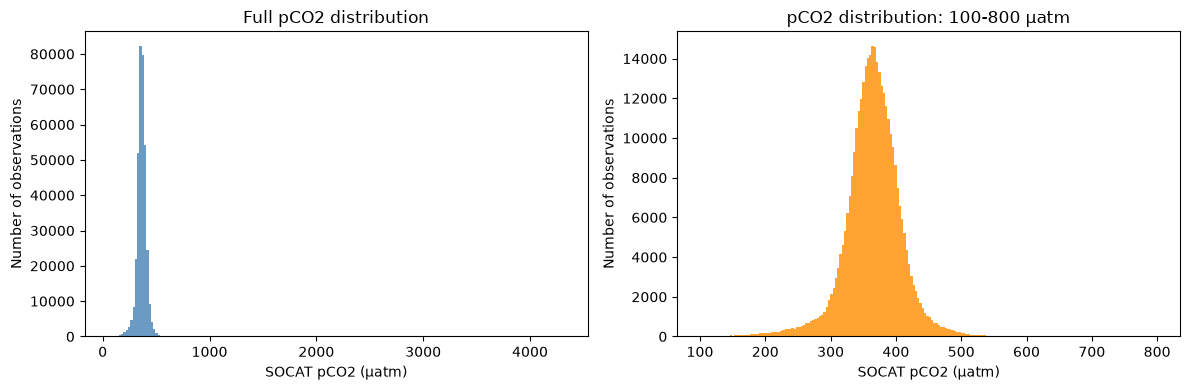

In [10]:
# Inspect extreme pco2 observations
print("Largest pCO2 values:")
largest_pco2 = socat_df.nlargest(20, "pco2")[["time", "lat", "lon", "pco2", "xco2", "delta_pco2"]]
display(largest_pco2)

print("Smallest pCO2 values:")
smallest_pco2 = socat_df.nsmallest(20, "pco2")[["time", "lat", "lon", "pco2", "xco2", "delta_pco2"]]
display(smallest_pco2)

# can remove outliers

# Plot full
fig, axes = plt.subplots( 1,  2, figsize=(12, 4))

axes[0].hist(
    socat_df["pco2"],
    bins=200,
    color="steelblue",
    alpha=0.8,
)
axes[0].set_xlabel("SOCAT pCO2 (µatm)")
axes[0].set_ylabel("Number of observations")
axes[0].set_title("Full pCO2 distribution")

axes[1].hist(
    socat_df["pco2"],
    bins=200,
    range=(100, 800),
    color="darkorange",
    alpha=0.8,
)
axes[1].set_xlabel("SOCAT pCO2 (µatm)")
axes[1].set_ylabel("Number of observations")
axes[1].set_title("pCO2 distribution: 100-800 µatm")

plt.tight_layout()
plt.show()

### Clip extreme values

Keep low values but the 2 strongly local coastal Florida values are remomved since they can dominate tree splits.

In [11]:
# PCO2_MAX_FOR_CLIM = 1500.0

# before_clip = len(socat_df)

# socat_df = socat_df.loc[socat_df["pco2"] <= PCO2_MAX_FOR_CLIM].copy()

# after_clip = len(socat_df)

# print("Rows before target clip:", f"{before_clip:,}")
# print("Rows after target clip:", f"{after_clip:,}")
# print("Rows removed:", f"{before_clip - after_clip:,}") #2

# print("\nLargest pCO₂ after clipping:")
# display(socat_df.nlargest(20, "pco2")[["time", "lat", "lon", "pco2", "xco2", "delta_pco2"]])

### Build monthly predictor climatologies
Create monthly climatology across all years 1993-2024.
E.g., `tos_clim[month=1]` : mean January SST for whole 1993-2024 period.

January predictor values are averaged across all Januaries, February, ... Decembers.

Result has dimensions:
` month = 12, lat = 180, lon = 360 `

In [12]:
CLIM_SOURCE_VARS = [
    "tos",
    "sos",
    "chlos",
    "mlotst",
]

# calculated using entire 1993-2024 period but means that validation 
# period contributes to predictor climatology -- leakage!
# need calculate predictor climatology using only training years
sat_clim = (
    ds_sat[CLIM_SOURCE_VARS]
    .groupby("time.month")
    .mean("time", skipna=True)
)

print("Monthly predictor climatology created")
print(sat_clim)

# instead sel train period only
sat_clim_train = (
    ds_sat.sel(time=slice("1993-01-01", "2018-12-31"))
    [["tos", "sos", "chlos", "mlotst"]]
    .groupby("time.month")
    .mean("time", skipna=True)
)

Monthly predictor climatology created
<xarray.Dataset> Size: 22MB
Dimensions:  (month: 12, lat: 180, lon: 360)
Coordinates:
  * month    (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Data variables:
    tos      (month, lat, lon) float64 6MB dask.array<chunksize=(1, 180, 360), meta=np.ndarray>
    sos      (month, lat, lon) float64 6MB dask.array<chunksize=(1, 180, 360), meta=np.ndarray>
    chlos    (month, lat, lon) float32 3MB dask.array<chunksize=(1, 180, 360), meta=np.ndarray>
    mlotst   (month, lat, lon) float64 6MB dask.array<chunksize=(1, 180, 360), meta=np.ndarray>


### Attach monthly climatological predictors to SOCAT observations
Based on calendar month and location. Each SOCAT observation received the average predictor conditions for its month latitude and longitude. For a March 2003 observation at (40N, 20W), the model received the average January conditions at that location (not exact Mar 2003 conditions)


In [13]:
obs_month = socat_df["month"].to_numpy()
obs_lat = xr.DataArray(socat_df["lat"].to_numpy(), dims="obs")
obs_lon = xr.DataArray(socat_df["lon"].to_numpy(), dims="obs")

obs_month_xr = xr.DataArray(obs_month, dims="obs")

for var in CLIM_SOURCE_VARS:
    sampled_clim = (
        sat_clim_train[var]
        .sel(
            month=obs_month_xr,
            lat=obs_lat,
            lon=obs_lon,
            method="nearest",
        )
        .compute()
    )

    socat_df[f"{var}_clim_obs"] = sampled_clim.values

    del sampled_clim
    gc.collect()

### Log transform Chl-a and MLD

Same as ResNet prediction model

In [14]:
# to avoid log10(0) and neg values
CHL_FLOOR = 1e-6
MLD_FLOOR = 1e-3

socat_df["chlos_clim_log_obs"] = np.log10(np.clip(socat_df["chlos_clim_obs"], CHL_FLOOR, None))
socat_df["mlotst_clim_log_obs"] = np.log10(np.clip(socat_df["mlotst_clim_obs"], MLD_FLOOR, None))

print("Climatological log predictors created")
print(socat_df[["chlos_clim_obs", "chlos_clim_log_obs", "mlotst_clim_obs", "mlotst_clim_log_obs"]].describe())

Climatological log predictors created
       chlos_clim_obs  chlos_clim_log_obs  mlotst_clim_obs  \
count   342868.000000       342868.000000    351917.000000   
mean         0.392128           -0.699374        42.107203   
std          0.722521            0.462079        44.050412   
min          0.012489           -1.903469        10.200000   
25%          0.088663           -1.052258        18.467321   
50%          0.180556           -0.743388        29.803558   
75%          0.393318           -0.405256        49.563439   
max         16.659863            1.221671       622.595758   

       mlotst_clim_log_obs  
count        351917.000000  
mean              1.506108  
std               0.292418  
min               1.008600  
25%               1.266404  
50%               1.474268  
75%               1.695161  
max               2.794206  


View climatological predictors attached

In [15]:
print("Climatological predictors attached")
display(
    socat_df[
        [
            "month",
            "lat",
            "lon",
            "tos_clim_obs",
            "sos_clim_obs",
            "chlos_clim_log_obs",
            "mlotst_clim_log_obs",
        ]
    ].head()
)

Climatological predictors attached


,month,lat,lon,tos_clim_obs,sos_clim_obs,chlos_clim_log_obs,mlotst_clim_log_obs
0,1,-68.5,70.5,-0.955870,33.883403,-0.150567,1.631902
1,1,-68.5,71.5,-0.723512,33.856305,0.074898,1.674164
2,1,-68.5,72.5,-0.476897,33.836573,0.137088,1.897294
3,1,-68.5,73.5,0.292379,33.793238,0.274790,1.796959
4,1,-68.5,74.5,0.813644,33.763277,0.367575,1.420217


### Spatial and seasonal features
Spatial: represent large scale geographic structure

Temporal: encode annual seasonal cycle without treating Dec and Jan far apart

In [16]:
# Spatial encodings
lat_rad = np.deg2rad(socat_df["lat"].to_numpy())
lon_rad = np.deg2rad(socat_df["lon"].to_numpy())

socat_df["A"] = np.sin(lon_rad)
socat_df["B"] = np.sin(lat_rad) * np.cos(lon_rad)
socat_df["C"] = -np.cos(lat_rad) * np.cos(lon_rad)

# Cyclical month encodings
month_angle = 2.0 * np.pi * (socat_df["month"].to_numpy() - 1)/ 12.0

socat_df["T0"] = np.sin(month_angle)
socat_df["T1"] = np.cos(month_angle)

print("Spatial and cyclical seasonal features added")

Spatial and cyclical seasonal features added


### Checks
Prevent NaNs in predictors to enter XGBoost

In [17]:
CLIM_FEATURES = [
    "tos_clim_obs",
    "sos_clim_obs",
    "chlos_clim_log_obs",
    "mlotst_clim_log_obs",
    "A",
    "B",
    "C",
    "T0",
    "T1",
]

CLIM_TARGET = "delta_pco2"

# Keep time so later cells can split observations by year
REQUIRED_COLUMNS = (
    ["time"]
    + CLIM_FEATURES
    + [CLIM_TARGET]
)

print("Missing-value check for climatology training")

missing_summary = (
    socat_df[REQUIRED_COLUMNS]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(missing_summary)

train_clim = (
    socat_df[REQUIRED_COLUMNS]
    .dropna()
    .copy()
)

# ensure pandas can use .dt.year below
train_clim["time"] = pd.to_datetime(train_clim["time"])

print("Rows before filtering:", f"{len(socat_df):,}")
print("Rows after filtering:", f"{len(train_clim):,}")
print("Training-table time range:", train_clim["time"].min(), "to", train_clim["time"].max())

assert len(train_clim) > 0

Missing-value check for climatology training


chlos_clim_log_obs     9732
mlotst_clim_log_obs     683
time                      0
sos_clim_obs              0
tos_clim_obs              0
A                         0
B                         0
C                         0
T0                        0
T1                        0
delta_pco2                0
dtype: int64

Rows before filtering: 352,600
Rows after filtering: 342,232
Training-table time range: 1993-01-16 12:00:00 to 2024-12-16 12:00:00


In [18]:
print(f"Training points after attaching predictors: {len(socat_df)}")
socat_df.head()

Training points after attaching predictors: 352600


,time,lat,lon,pco2,month,time_month,xco2,delta_pco2,tos_clim_obs,sos_clim_obs,chlos_clim_obs,mlotst_clim_obs,chlos_clim_log_obs,mlotst_clim_log_obs,A,B,C,T0,T1
0,1993-01-16 12:00:00,-68.5,70.5,250.002814,1,1993-01-01,354.743347,-104.740533,-0.955870,33.883403,0.707022,42.845190,-0.150567,1.631902,0.942641,-0.310580,-0.122341,0.0,1.0
1,1993-01-16 12:00:00,-68.5,71.5,277.745735,1,1993-01-01,354.743347,-76.997612,-0.723512,33.856305,1.188222,47.224152,0.074898,1.674164,0.948324,-0.295226,-0.116293,0.0,1.0
2,1993-01-16 12:00:00,-68.5,72.5,269.766776,1,1993-01-01,354.743347,-84.976571,-0.476897,33.836573,1.371158,78.939466,0.137088,1.897294,0.953717,-0.279782,-0.110209,0.0,1.0
3,1993-01-16 12:00:00,-68.5,73.5,264.016365,1,1993-01-01,354.743347,-90.726982,0.292379,33.793238,1.882738,62.655431,0.274790,1.796959,0.958820,-0.264253,-0.104092,0.0,1.0
4,1993-01-16 12:00:00,-68.5,74.5,235.189827,1,1993-01-01,354.743347,-119.553521,0.813644,33.763277,2.331178,26.315805,0.367575,1.420217,0.963630,-0.248643,-0.097943,0.0,1.0


In [19]:
print("pCO2 attributes:")
print(ds_socat[PCO2_VAR].attrs)

print("pCO2 min:", socat_df["pco2"].min())
print("pCO2 max:", socat_df["pco2"].max())

print("delta_pco2 min:", socat_df["delta_pco2"].min())
print("delta_pco2 max:", socat_df["delta_pco2"].max())

pCO2 attributes:
{'conversion': 'Bennington et al. (2022) Eq. 1, Weiss (1974) virial coefficients', 'long_name': 'Surface ocean pCO₂ converted from fCO₂', 'patm_source': 'ERA5 mean_sea_level_pressure', 'sst_source': 'MULTIOBS ARMOR3D', 'units': 'µatm'}
pCO2 min: 44.67148770413978
pCO2 max: 4324.314487612836
delta_pco2 min: -370.5280667392196
delta_pco2 max: 3933.908878481977


## 3. XGBoost Climatology Model

Learns delta pco2 clim from clim predictors, location, and month.

### Train and validation split

Hold out complete years to avoid mixing same year's observations betwween training and validation

In [20]:
train_mask = (train_clim["time"].dt.year <= 2018)
valid_mask = (train_clim["time"].dt.year >= 2019) & (train_clim["time"].dt.year <= 2021)
test_mask = (train_clim["time"].dt.year >= 2022) & (train_clim["time"].dt.year <= 2024)

X_train = train_clim.loc[train_mask, CLIM_FEATURES]
y_train = train_clim.loc[train_mask, CLIM_TARGET]

X_valid = train_clim.loc[valid_mask, CLIM_FEATURES]
y_valid = train_clim.loc[valid_mask, CLIM_TARGET]

X_test = train_clim.loc[test_mask, CLIM_FEATURES]
y_test = train_clim.loc[test_mask, CLIM_TARGET]

print("Train rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Test rows:", len(X_test))

Train rows: 270120
Validation rows: 38185
Test rows: 33927


In [21]:
X_clim = train_clim[CLIM_FEATURES]
y_clim = train_clim[CLIM_TARGET]

clim_model = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    n_jobs=8,
    random_state=SEED,
    tree_method="hist",
)

# fit on train period
clim_model.fit(
    X_train,
    y_train,
    eval_set=[
        (X_train, y_train),
        (X_valid, y_valid)
    ],
    verbose=False,
)
train_clim["delta_pco2_clim_fit"] = clim_model.predict(X_clim)

print("XGBoost climatology model fitted")
print("Training rows:", f"{len(train_clim):,}")
print("Training target range:", float(y_clim.min()), "to", float(y_clim.max()))
print("Training prediction range:", train_clim["delta_pco2_clim_fit"].min(), "to", train_clim["delta_pco2_clim_fit"].max())

XGBoost climatology model fitted
Training rows: 342,232
Training target range: -370.5280667392196 to 867.8673256061634
Training prediction range: -271.77304 to 256.73322


### Feature importance

WHat did the climatology model learn?

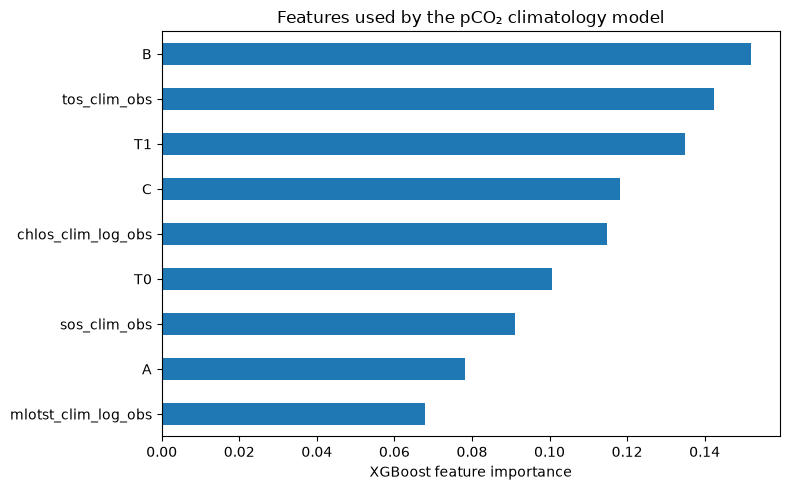

B                      0.151838
tos_clim_obs           0.142407
T1                     0.134899
C                      0.118200
chlos_clim_log_obs     0.114728
T0                     0.100693
sos_clim_obs           0.091143
A                      0.078251
mlotst_clim_log_obs    0.067841
dtype: float32

In [22]:
feature_importance = (
    pd.Series(
        clim_model.feature_importances_,
        index=CLIM_FEATURES,
    )
    .sort_values(ascending=True)
)

feature_importance.plot(kind="barh", figsize=(8, 5))

plt.xlabel("XGBoost feature importance")
plt.title("Features used by the pCO₂ climatology model")
plt.tight_layout()
plt.show()

display(feature_importance.sort_values(ascending=False))

### Calculate metrics on validation and test

In [23]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "bias": np.mean(y_pred - y_true),
        "R2": r2_score(y_true, y_pred),
    }

valid_pred = clim_model.predict(X_valid)
test_pred = clim_model.predict(X_test)

print("Validation metrics:")
print(regression_metrics(y_valid, valid_pred))

print("Test metrics:")
print(regression_metrics(y_test, test_pred))

Validation metrics:
{'MAE': 14.960236140344902, 'RMSE': np.float64(24.87383061223148), 'bias': np.float64(2.1259440745563754), 'R2': 0.7095270668099356}
Test metrics:
{'MAE': 17.032116266314524, 'RMSE': np.float64(27.430492727164307), 'bias': np.float64(2.728840021118413), 'R2': 0.6933308467278827}


### Visual check
Does the climatology model learn a sensible average reltionship instead of producing extreme or constarnt predictions?

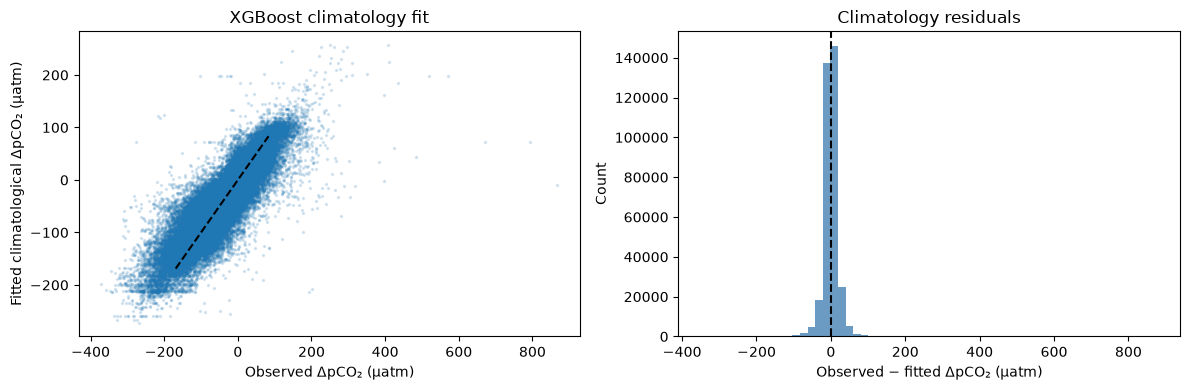

Climatology residual mean: -0.510055807115377
Climatology residual standard deviation: 19.807208838118814


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Observed versus fitted climatological target
axes[0].scatter(
    train_clim["delta_pco2"],
    train_clim["delta_pco2_clim_fit"],
    s=2,
    alpha=0.15,
)

lims = [
    np.nanpercentile(train_clim["delta_pco2"], 1),
    np.nanpercentile(train_clim["delta_pco2"], 99),
]

axes[0].plot(
    lims,
    lims,
    color="black",
    linestyle="--",
)

axes[0].set_xlabel("Observed ΔpCO₂ (µatm)")
axes[0].set_ylabel("Fitted climatological ΔpCO₂ (µatm)")
axes[0].set_title("XGBoost climatology fit")

# Residual distribution
residuals = train_clim["delta_pco2"] - train_clim["delta_pco2_clim_fit"]

axes[1].hist(residuals, bins=60, color="steelblue", alpha=0.8)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_xlabel("Observed − fitted ΔpCO₂ (µatm)")
axes[1].set_ylabel("Count")
axes[1].set_title("Climatology residuals")

plt.tight_layout()
plt.show()

print("Climatology residual mean:", residuals.mean())
print("Climatology residual standard deviation:", residuals.std())

### Final fit: all valid observations, 1993–2024

Previous model was fitted only on 1993-2018 for validation and test metrics with remaining years. Here we use all 1993-2024 valid observations to generate climatology and thermal component to be used for the satellite predictions.

In [25]:
X_all = train_clim[CLIM_FEATURES]
y_all = train_clim[CLIM_TARGET]

clim_model_final = xgb.XGBRegressor(
    objective="reg:squarederror",
    n_estimators=500,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1.0,
    n_jobs=8,
    random_state=SEED,
    tree_method="hist",
)

clim_model_final.fit(
    X_all,
    y_all,
    verbose=False,
)

print(f"Final production model fitted on: {len(X_all):,} valid SOCAT observations from 1993-2024")
print("Final target range:", float(y_all.min()), "to", float(y_all.max()))

Final production model fitted on: 342,232 valid SOCAT observations from 1993-2024
Final target range: -370.5280667392196 to 867.8673256061634


### Create the full 12-month global climatology

Model evaluated at every grid cell for each of the 12 months. Result is `delta_pco2_clim(month, lat, lon)`. E.g., `delta_pco2_clim.sel(month=1)` is predicted Jan climatology over the full global grid.

In [26]:
def make_spatial_features(lat, lon, month):
    """
    Create spatial and cyclical month features on the full target grid.
    """
    lat_grid, lon_grid = np.meshgrid(
        lat,
        lon,
        indexing="ij",
    )

    lat_rad = np.deg2rad(lat_grid)
    lon_rad = np.deg2rad(lon_grid)

    month_angle = 2.0 * np.pi  * (month-1) / 12.0

    return {
        "A": np.sin(lon_rad),
        "B": np.sin(lat_rad) * np.cos(lon_rad),
        "C": -np.cos(lat_rad) * np.cos(lon_rad),
        "T0": np.full_like(
            lat_grid,
            np.sin(month_angle),
            dtype=float,
        ),
        "T1": np.full_like(
            lat_grid,
            np.cos(month_angle),
            dtype=float,
        )
    }


lat_values = ds_sat.lat.values
lon_values = ds_sat.lon.values

clim_predictions = []

for month in range(1, 13):
    print(f"Predicting climatology for month {month:02d}")

    monthly_predictors = sat_clim.sel(month=month)

    feature_dict = {
        "tos_clim_obs": monthly_predictors["tos"].values.ravel(),
        "sos_clim_obs": monthly_predictors["sos"].values.ravel(),
        "chlos_clim_log_obs": np.log10(
            np.clip(
                monthly_predictors["chlos"].values.ravel(),
                CHL_FLOOR,
                None
            )
        ),
        "mlotst_clim_log_obs": np.log10(
            np.clip(
                monthly_predictors["mlotst"].values.ravel(),
                MLD_FLOOR,
                None
            )
        )
    }

    spatial_features = make_spatial_features(
        lat_values,
        lon_values,
        month
    )

    for name, values in spatial_features.items():
        feature_dict[name] = values.ravel()

    grid_features = pd.DataFrame(feature_dict)[CLIM_FEATURES]

    # XGBoost cant predict rows with NaN values - keep track of missing predictor locations
    valid_grid = grid_features.notna().all(axis=1)

    month_prediction = np.full(
        len(grid_features),
        np.nan,
        dtype=np.float32
    )

    month_prediction[valid_grid.to_numpy()] = (
        clim_model_final.predict(grid_features.loc[valid_grid])
    )

    month_prediction = month_prediction.reshape(
        len(lat_values),
        len(lon_values)
    )

    clim_predictions.append(month_prediction)

delta_pco2_clim = xr.DataArray(
    np.stack(clim_predictions),
    dims=("month", "lat", "lon"),
    coords={
        "month": np.arange(1, 13),
        "lat": ds_sat.lat,
        "lon": ds_sat.lon,
    },
    name="delta_pco2_clim",
    attrs={
        "long_name": "Monthly climatology of detrended ocean pCO2",
        "units": "uatm",
        "method": (
            "XGBoost regression using monthly climatological "
            "satellite predictors, spatial features, and month features"
        ),
        "period": f"{START_DATE} to {END_DATE}",
    },
)

print("Full global monthly climatology created")
print(delta_pco2_clim)

Predicting climatology for month 01
Predicting climatology for month 02
Predicting climatology for month 03
Predicting climatology for month 04
Predicting climatology for month 05
Predicting climatology for month 06
Predicting climatology for month 07
Predicting climatology for month 08
Predicting climatology for month 09
Predicting climatology for month 10
Predicting climatology for month 11
Predicting climatology for month 12
Full global monthly climatology created
<xarray.DataArray 'delta_pco2_clim' (month: 12, lat: 180, lon: 360)> Size: 3MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, na

### Climatology smoothing

Smooth only along the cyclical seasonal month dimension to reduce overfitting month to month tree artefacts, like Gregor. Here, 3-month temporal smoothing and 3x3 spatial smoothing.

In [27]:
delta_pco2_clim_smooth = (
    delta_pco2_clim
    .rolling(
        month=3,
        center=True,
        min_periods=1,
    )
    .mean()
    .rolling(
        lat=3,
        lon=3,
        center=True,
        min_periods=1,
    )
    .mean()
)

delta_pco2_clim_smooth.name = "delta_pco2_clim"

print("Smoothed climatology created")

Smoothed climatology created


### Construct full satellite pco2 baseline

In [28]:
xco2_full = (
    ds_xco2[XCO2_VAR]
    .transpose("time", "lat", "lon")
    .astype(np.float32)
)

# # correct
# xco2_clim = (
#     xco2_full
#     .groupby("time.month")
#     .mean("time")
# )

assert xco2_full.sizes["time"] == 384
assert xco2_full.sizes["lat"] == 180
assert xco2_full.sizes["lon"] == 360

# NOAA MBL should be uniform in longitude
assert np.allclose(
    xco2_full.isel(lon=0).values,
    xco2_full.isel(lon=-1).values,
    equal_nan=True,
)

print("Latitude-resolved xCO2 field:", xco2_full.shape)

month_index = xr.DataArray(
    ds_sat.time.dt.month.values,
    dims="time",
    coords={"time": ds_sat.time},
)

delta_pco2_clim_full = (
    delta_pco2_clim_smooth
    .sel(month=month_index)
    .assign_coords(time=ds_sat.time)
    .transpose("time", "lat", "lon")
    .astype(np.float32)
)

# correct
# Match 12-month climatology to each actual month
delta_pco2_clim_full = (
    delta_pco2_clim_smooth
    .sel(month=month_index)
    .assign_coords(time=ds_sat.time)
    .transpose("time", "lat", "lon")
)

pco2_baseline = (
    delta_pco2_clim_full
    + xco2_full
).rename("pco2_baseline")

pco2_baseline.attrs.update({
    "long_name": (
        "Monthly pCO2 baseline from smoothed XGBoost "
        "detrended climatology plus NOAA atmospheric CO2"
    ),
    "units": "uatm",
    "formula": (
        "delta_pco2_clim_smooth(month, lat, lon) "
        "+ atm_co2_xco2(time, lat, lon)"
    ),
    "role": (
        "Monthly climatological pCO2 field used to derive "
        "the long-term reference pCO2 field for the thermal component"
    )
})

print("Satellite pCO2 baseline created")
print("Shape:", pco2_baseline.shape)
print("Range:", float(pco2_baseline.min()), "to", float(pco2_baseline.max()))
print("Mean:", float(pco2_baseline.mean()))

Latitude-resolved xCO2 field: (384, 180, 360)
Satellite pCO2 baseline created
Shape: (384, 180, 360)
Range: 112.57658386230469 to 1058.0712890625
Mean: 365.2645568847656


### Calculate the thermal pco2 component

Using the long-term mean pCO2 field from the XGBoost climatology and the local satellite SST anomaly.

In [29]:
# correct 
# Monthly climatological ocean-atmosphere difference
# + actual atmospheric CO2 for that month
pco2_reference = (
    delta_pco2_clim_full + xco2_full
)

# # Long-term reference pCO2 field from the XGBoost baseline
# pco2_reference = (
#     pco2_baseline
#     .mean(dim="time")
#     .transpose("lat", "lon")
#     .astype(np.float32)
#     .rename("pco2_reference")
# )

print("Reference pCO2:")
print(
    "range:",
    float(pco2_reference.min()),
    "to",
    float(pco2_reference.max()),
)
print("global mean:", float(pco2_reference.mean()))

# SST climatology
sst_clim = (
    ds_sat["tos"]
    .groupby("time.month")
    .mean("time")
)

# match each actual month to its clim month
sst_clim_full = (
    sst_clim
    .sel(month=month_index)
    .assign_coords(time=ds_sat.time)
    .transpose("time", "lat", "lon")
)

# Long-term mean satellite SST
# sst_reference = (
#     ds_sat["tos"]
#     .mean(dim="time")
#     .transpose("lat", "lon")
#     .astype(np.float32)
#     .rename("sst_reference")
# )

# print("SST reference range:")
# print(
#     float(sst_reference.min()),
#     "to",
#     float(sst_reference.max()),
# )

# Satellite SST anomaly
sst_anomaly = ds_sat["tos"] - sst_clim_full
# sst_anomaly = (
#     ds_sat["tos"] - sst_reference
# ).astype(np.float32)

# Convert SST anomaly into the thermal pCO2 component
pco2_thermal = (
    pco2_reference
    * np.exp(0.0423 * sst_anomaly)
).rename("pco2_thermal")


# just to make sure 
pco2_thermal = (
    pco2_thermal
    .transpose("time", "lat", "lon")
    .astype(np.float32)
)

pco2_thermal.attrs.update({
    "long_name": "Satellite thermal pCO2 component",
    "units": "uatm",
    "formula": (
        "XGBoost reference pCO2 * "
        "exp(0.0423 * satellite SST anomaly)"
    ),
    "temperature_sensitivity": "0.0423 K-1",
    "reference_source": "XGBoost pCO2 climatology",
})

print("Satellite thermal pCO2 component created")

Reference pCO2:
range: 112.57658386230469 to 1058.0712890625
global mean: 365.2645568847656
Satellite thermal pCO2 component created


#### Thermal component diagnostics

In [30]:
print("\nSatellite thermal component:")
print(pco2_thermal)
print("range:", float(pco2_thermal.min()), "to", float(pco2_thermal.max()))
print("mean:", float(pco2_thermal.mean()))

print("\nXGBoost reference pCO2:")
print("range:", float(pco2_reference.min()), "to", float(pco2_reference.max()))
print("mean:", float(pco2_reference.mean()))

print("\nSST anomaly:")
print("range:", float(sst_anomaly.min()), "to", float(sst_anomaly.max()))

print("\nThermal component quantiles:")
print(np.nanpercentile(pco2_thermal.values, [1, 5, 25, 50, 75, 95, 99]))


Satellite thermal component:
<xarray.DataArray 'pco2_thermal' (time: 384, lat: 180, lon: 360)> Size: 100MB
dask.array<astype, shape=(384, 180, 360), dtype=float32, chunksize=(1, 180, 360), chunktype=numpy.ndarray>
Coordinates:
  * time     (time) datetime64[ns] 3kB 1993-01-01 1993-02-01 ... 2024-12-01
    month    (time) int64 3kB dask.array<chunksize=(12,), meta=np.ndarray>
  * lat      (lat) float64 1kB -89.5 -88.5 -87.5 -86.5 ... 86.5 87.5 88.5 89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes: (12/13)
    method:                   XGBoost regression using monthly climatological...
    period:                   1993-01-01 to 2024-12-31
    citation:                 Lan, X., Tans, P., Thoning, K., & NOAA Global M...
    reference_scale:          X2019
    source:                   NOAA GML Greenhouse Gas Marine Boundary Layer S...
    spatial_representation:   Latitude-dependent atmospheric CO2 broadcast un...
    ...                   

## 4. Visualisations

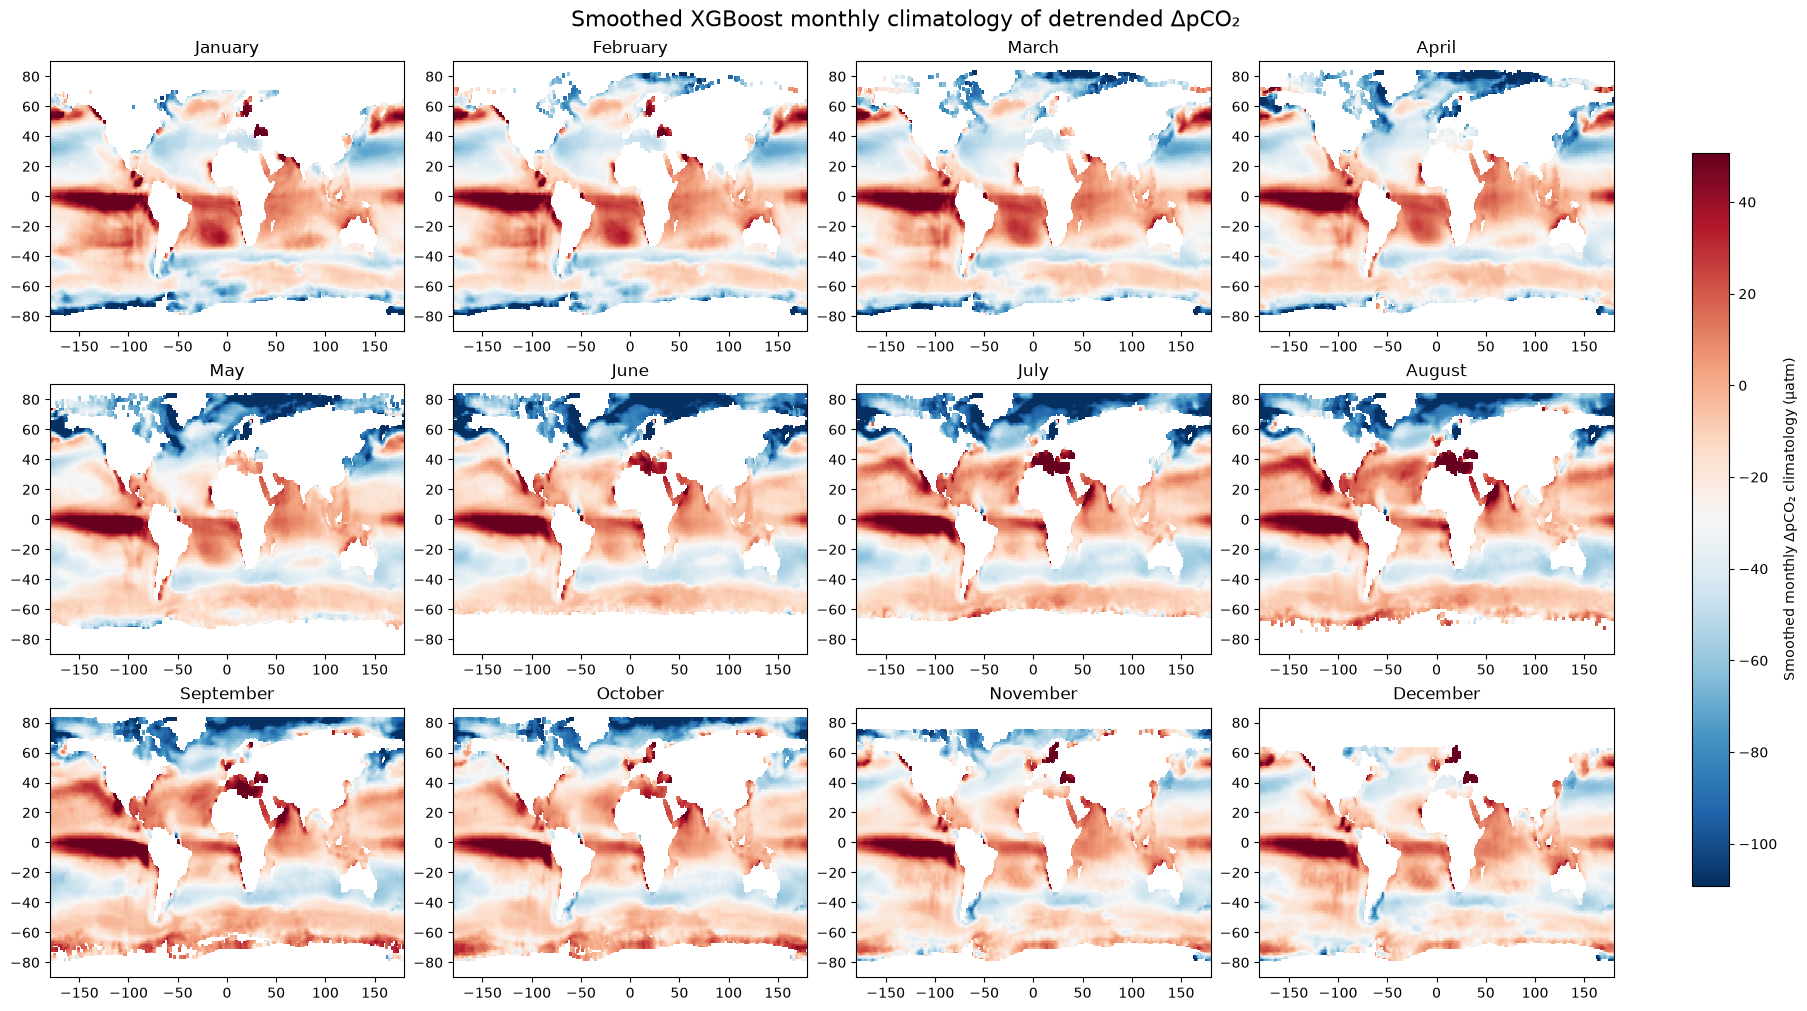

In [31]:
fig, axes = plt.subplots(3, 4, figsize=(18, 10), constrained_layout=True)

vmin = float(np.nanpercentile(delta_pco2_clim_smooth.values, 2))
vmax = float(np.nanpercentile(delta_pco2_clim_smooth.values, 98))

for month, ax in zip(range(1, 13), axes.flat):
    delta_pco2_clim_smooth.sel(month=month).plot(
        ax=ax,
        cmap="RdBu_r",
        vmin=vmin,
        vmax=vmax,
        add_colorbar=False,
    )

    ax.set_title(pd.Timestamp(2000, month, 1).strftime("%B"))
    ax.set_xlabel("")
    ax.set_ylabel("")

# Shared colourbar
sm = plt.cm.ScalarMappable(cmap="RdBu_r", norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])

fig.colorbar(sm, ax=axes, label="Smoothed monthly ΔpCO₂ climatology (µatm)", shrink=0.8)
fig.suptitle("Smoothed XGBoost monthly climatology of detrended ΔpCO₂", fontsize=16)
plt.show()

### Plot thermal component maps

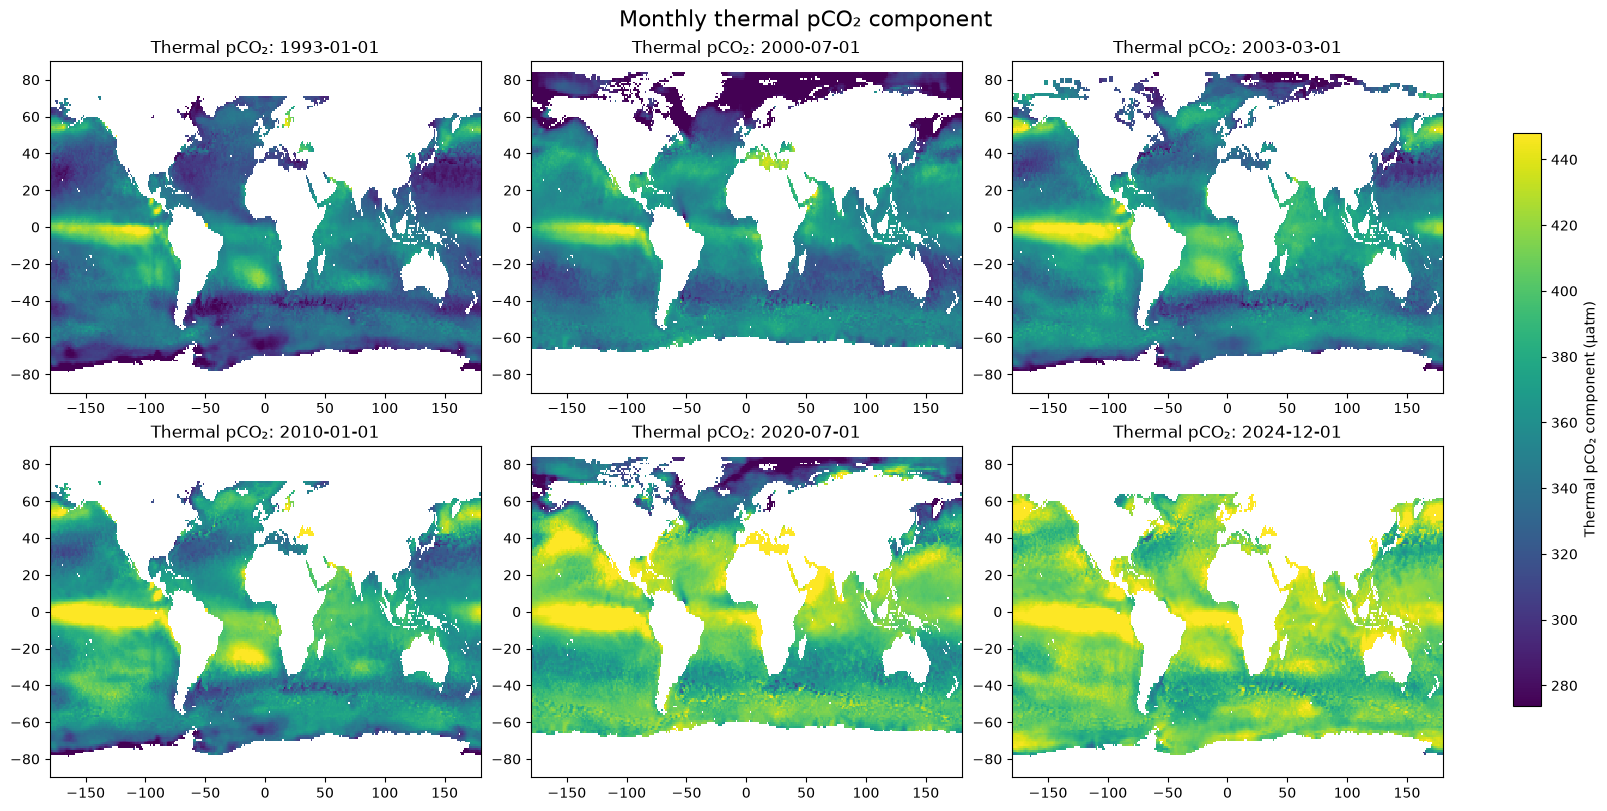

In [32]:
# Select representative months for visual inspection.
thermal_dates = [
    "1993-01-01",
    "2000-07-01",
    "2003-03-01",
    "2010-01-01",
    "2020-07-01",
    "2024-12-01",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)

thermal_min = float(np.nanpercentile(pco2_thermal.values, 2))
thermal_max = float(np.nanpercentile(pco2_thermal.values, 98))

for ax, date in zip(axes.flat, thermal_dates):
    pco2_thermal.sel(time=date).plot(
        ax=ax,
        cmap="viridis",
        vmin=thermal_min,
        vmax=thermal_max,
        add_colorbar=False,
    )

    ax.set_title(f"Thermal pCO₂: {date}")
    ax.set_xlabel("")
    ax.set_ylabel("")

sm = plt.cm.ScalarMappable(
    cmap="viridis",
    norm=plt.Normalize(
        vmin=thermal_min,
        vmax=thermal_max,
    )
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=axes,
    label="Thermal pCO₂ component (µatm)",
    shrink=0.8,
)

fig.suptitle(
    "Monthly thermal pCO₂ component",
    fontsize=16,
)

plt.show()

### Plot thermal time series

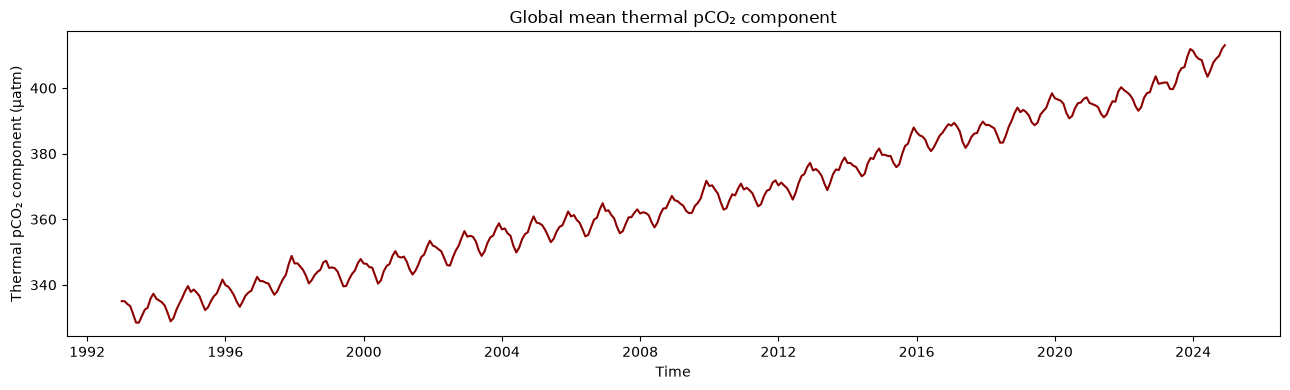

Thermal global-mean summary:


count    384.000000
mean     366.203156
std       21.929781
min      328.475220
25%      346.810143
50%      363.306442
75%      385.555908
max      413.071472
Name: pco2_thermal, dtype: float64

In [33]:
thermal_global_mean = (
    pco2_thermal
    .mean(dim=["lat", "lon"], skipna=True)
)

fig, ax = plt.subplots(figsize=(13, 4))

thermal_global_mean.plot(ax=ax, color="darkred")

ax.set_title("Global mean thermal pCO₂ component")
ax.set_ylabel("Thermal pCO₂ component (µatm)")
ax.set_xlabel("Time")

plt.tight_layout()
plt.show()

print("Thermal global-mean summary:")
display(thermal_global_mean.to_series().describe())

### Check thermal values at SOCAT observations

Sample the gridded thermal field at each SOCAT observation.

In [34]:
thermal_at_obs = (
    pco2_thermal
    .sel(
        time=xr.DataArray(
            socat_df["time_month"].values,
            dims="obs",
        ),
        lat=xr.DataArray(
            socat_df["lat"].values,
            dims="obs",
        ),
        lon=xr.DataArray(
            socat_df["lon"].values,
            dims="obs",
        ),
        method="nearest",
    )
    .compute()
)

socat_df["pco2_thermal"] = thermal_at_obs.values

print("Thermal component at SOCAT observations:")
display(socat_df["pco2_thermal"].describe())

Thermal component at SOCAT observations:


count    349075.000000
mean        366.562286
std          38.300285
min         142.456680
25%         344.264343
50%         367.094574
75%         390.485474
max         607.598816
Name: pco2_thermal, dtype: float64

## 5. Save final product

Save the XGBoost climatology, the resulting pCO2 baseline and reference fields, and the satellite-derived thermal pCO2 component.

The ResNet inference notebook uses `pco2_thermal` as the thermal component added to the predicted non-thermal residual.

In [38]:
thermal_output = xr.Dataset({
    "delta_pco2_clim": (
        delta_pco2_clim.astype(np.float32)
    ),
    "delta_pco2_clim_smooth": (
        delta_pco2_clim_smooth.astype(np.float32)
    ),
    "pco2_baseline": (
        pco2_baseline.astype(np.float32)
    ),
    "pco2_reference": (
        pco2_reference.astype(np.float32)
    ),
    "pco2_thermal": (
        pco2_thermal.astype(np.float32)
    )
})

thermal_output.attrs.update({
    "title": (
        "Monthly 1-degree XGBoost pCO2 climatology, "
        "reference field, and thermal component"
    ),
    "method": (
        "XGBoost monthly detrended pCO2 climatology with "
        "NOAA atmospheric CO2 restoration and SST-based "
        "thermal decomposition"
    ),
    "period": f"{START_DATE} to {END_DATE}",
    "resolution": "monthly, 1 degree",
    "longitude_convention": "-180 to 180",
    "atmospheric_reference": (
        "NOAA GML Marine Boundary Layer reference"
    ),
    "target_variable": "SOCAT pco2_ave_weighted",
    "temperature_sensitivity": "0.0423 K-1",
    "thermal_formula": (
        "pco2_reference * exp(0.0423 * SST_anomaly"
    ),
    "thermal_role": (
        "Thermal pCO2 component added to the "
        "ResNet-predicted non-thermal component"
    )
})

# thermal_output_path = os.path.join(
#     THERMAL_SAVE_DIR,
#     "pco2_thermal_xgboost_1993_2024_1deg_monthly.zarr",
# )

# if os.path.exists(thermal_output_path):
#     shutil.rmtree(thermal_output_path)

for var in thermal_output.data_vars:
    thermal_output[var].encoding = {}

for coord in thermal_output.coords:
    thermal_output[coord].encoding = {}

thermal_output.encoding = {}

thermal_output.to_zarr(
    THERMAL_SAVE_PATH,
    mode="w",
    consolidated=True,
)

print("Saved:", THERMAL_SAVE_PATH)
print("Variables:", list(thermal_output.data_vars))

/data/antwerpen/212/vsc21282/conda-envs/hydra-pco2/lib/python3.11/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


Saved: /scratch/antwerpen/grp/ap_vliz_research/PPFC/evie.stergiopoulou/HYDRA-pCO2/data/processed/xgboost_thermal/pco2_thermal_xgboost_1993_2024_1deg_monthly.zarr
Variables: ['delta_pco2_clim', 'delta_pco2_clim_smooth', 'pco2_baseline', 'pco2_reference', 'pco2_thermal']


### Reopen and validate Zarr

In [41]:
saved = xr.open_zarr(
    THERMAL_SAVE_PATH,
    consolidated=True,
)

print(saved)
print("Dimensions:", dict(saved.sizes))
print("Time:", str(saved.time.values[0]), "to", str(saved.time.values[-1]))
print("Variables:", list(saved.data_vars))

required_variables = [
    "delta_pco2_clim",
    "delta_pco2_clim_smooth",
    "pco2_baseline",
    "pco2_reference",
    "pco2_thermal",
]

expected_dims = {
    "delta_pco2_clim": ("month", "lat", "lon"),
    "delta_pco2_clim_smooth": ("month", "lat", "lon"),
    "pco2_baseline": ("time", "lat", "lon"),
    "pco2_reference": ("time", "lat", "lon"),
    "pco2_thermal": ("time", "lat", "lon"),
}

missing_variables = [
    variable
    for variable in required_variables
    if variable not in saved.data_vars
]

assert not missing_variables, (
    f"Missing variables: {missing_variables}"
)

for variable, dims in expected_dims.items():
    assert saved[variable].dims == dims, (
        f"{variable}: got {saved[variable].dims}, "
        f"expected {dims}"
    )

assert saved.sizes["month"] == 12
assert saved.sizes["time"] == 384
assert saved.sizes["lat"] == 180
assert saved.sizes["lon"] == 360

print("All climatology variables and dimensions are correct")

<xarray.Dataset> Size: 305MB
Dimensions:                 (month: 12, lat: 180, lon: 360, time: 384)
Coordinates:
  * month                   (month) int64 96B 1 2 3 4 5 6 7 8 9 10 11 12
  * lat                     (lat) float64 1kB -89.5 -88.5 -87.5 ... 88.5 89.5
  * lon                     (lon) float64 3kB -179.5 -178.5 ... 178.5 179.5
  * time                    (time) datetime64[ns] 3kB 1993-01-01 ... 2024-12-01
Data variables:
    delta_pco2_clim         (month, lat, lon) float32 3MB dask.array<chunksize=(6, 90, 180), meta=np.ndarray>
    delta_pco2_clim_smooth  (month, lat, lon) float32 3MB dask.array<chunksize=(6, 90, 180), meta=np.ndarray>
    pco2_baseline           (time, lat, lon) float32 100MB dask.array<chunksize=(48, 45, 90), meta=np.ndarray>
    pco2_reference          (time, lat, lon) float32 100MB dask.array<chunksize=(48, 45, 90), meta=np.ndarray>
    pco2_thermal            (time, lat, lon) float32 100MB dask.array<chunksize=(1, 180, 360), meta=np.ndarray>
Attributes